## Plots of the model

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from model import Config, Park
from behaviours import run_scenario, RULES
from metrics import summarize
from main import run_all

## calibration check capacity

In [ ]:
rows = []
for seed in range(100):
    cfg = Config(grid_capacity=30000,seed=seed)
    hist, park = run_scenario(cfg,seed)
    rows.append({
        "seed": seed,
        "initial_load":
            park.initial_load,
        "initial_utilization":
            park.initial_utilization,
    })

calibration = pd.DataFrame(rows)

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    calibration["initial_utilization"],
    bins=20
)

plt.axvline(
    1.0,
    color="red",
    linestyle="--",
    label="Capacity limit"
)

plt.xlabel("Initial utilization")
plt.ylabel("Number of runs")
plt.title("Initial utilization across random seeds")
plt.legend()
plt.show()

In [ ]:
# baseline scenario
cfg = Config(seed=42,scenario="COMBINED")
hist, park = run_scenario(cfg,42)

In [ ]:
results = run_all(Config(n_replications=50,seed=42))
pd.DataFrame(results)

In [ ]:
def run_replications(cfg, scenario):
    rows = []
    for r in range(cfg.n_replications):
        seed = (cfg.seed or 0) + r
        cfg.scenario = scenario
        hist, park = run_scenario(cfg,seed,)

        rows.append(summarize(hist,park,))

    return pd.DataFrame(rows)

## Figure 1: compare scenarios

In [ ]:
rows = []

cfg = Config(
    n_replications=20,
    seed=42
)
for scenario in RULES:
    df = run_replications(
        cfg,
        scenario
    )
    rows.append({
        "scenario": scenario,
        "utilization":
            df["mean_utilization"].mean(),
        "realized":
            df["realized_expansion"].mean(),
        "unrealized":
            df["unrealized_expansion"].mean(),
        "queue":
            df["queue_length"].mean(),
        "cooperation":
            df["cooperation_count"].mean(),
        "final_demand":
            df["final_demand"].mean(),
        "final_production":
            df["final_production"].mean(),
    })

results = pd.DataFrame(rows)
results

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="utilization"
)

plt.title(
    "Mean grid utilization by scenario"
)

plt.show()

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="unrealized"
)

plt.title(
    "Blocked expansion attempts"
)

plt.show()

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="queue"
)

plt.title(
    "Firms waiting for grid capacity"
)

plt.show()


In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="cooperation"
)

plt.title(
    "Energy hub participation"
)

plt.show()

## Figure 2: total net load per time step

In [ ]:
cfg = Config(seed=42)

fig, axes = plt.subplots(2,2,figsize=(10,8))
axes = axes.flatten()

for ax, scenario in zip(axes,RULES.keys()):
    cfg.scenario = scenario
    hist, park = run_scenario(cfg,42)

    final_util = (hist[-1]["net_load"] / hist[-1]["capacity"])
    ax.plot([h["t"] for h in hist],[h["net_load"] for h in hist],label="Net load")
    ax.plot([h["t"] for h in hist],[h["capacity"] for h in hist],"--",label="Capacity")
    ax.set_title(f"{scenario}\nFinal utilisation: {final_util:.1%}")
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Net load")

plt.tight_layout()
plt.show()


In [ ]:
n_runs = 50
cfg = Config()
fig, axes = plt.subplots(2,2,figsize=(10, 8))
axes = axes.flatten()

for ax, scenario in zip(axes,RULES.keys()):
    all_series = []
    for r in range(n_runs):
        cfg.scenario = scenario
        hist, park = run_scenario(cfg,r,)
        all_series.append([h["net_load"] for h in hist])
    all_series = np.array(all_series)
    mean = all_series.mean(axis=0)
    std = all_series.std(axis=0)
    time = np.arange(len(mean))
    final_load = mean[-1]
    final_util = final_load / cfg.grid_capacity
    ax.plot(time,mean,color="tab:blue",label="Mean net load",)
    ax.fill_between(
        time,
        mean - std,
        mean + std,
        color="tab:blue",
        alpha=0.25,
        label="±1 SD",
    )
    ax.axhline(
        cfg.grid_capacity,
        linestyle="--",
        color="orange",
        label="Capacity",
    )
    ax.set_title(
        f"{scenario}\n"
        f"Final utilisation: {final_util:.1%}\n"
        f"Final net load: {final_load:,.0f}"
    )
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Net load")

plt.tight_layout()
plt.show()

## Figure 3: spatial heatmap

In [ ]:
cfg = Config(seed=42,scenario="COMBINED")

hist, park = run_scenario(cfg,42)

plt.figure(figsize=(8,8))

sns.heatmap(
    park.load_grid(),
    cmap="RdBu_r",
    center=0
)

plt.title("Spatial distribution of net load")

plt.show()

## Figure 4: different metrics phase diagram

100%|██████████| 11/11 [00:17<00:00,  1.56s/it]


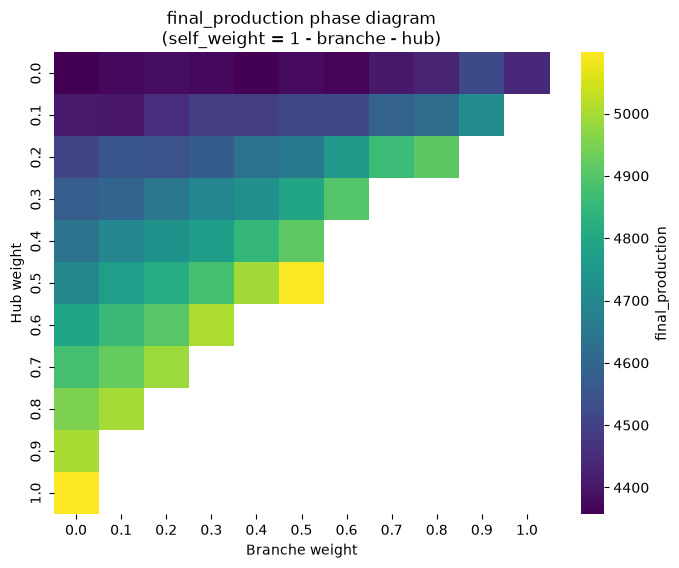

In [8]:
branches = np.arange(0, 1.05, 0.1)
hubs = np.arange(0, 1.05, 0.1)

runs_per_cell = 10
#metric = "mean_utilization"
#metric = "realized_expansion"
#metric = "queue_length"
metric = "final_production"
# metric = "final_demand"

heat = np.full((len(hubs),len(branches)),np.nan,)
for i, hub in enumerate(tqdm(hubs)):
    for j, branche in enumerate(branches):
        self_weight = 1 - hub - branche
        # invalid combinations
        if self_weight < 0:
            continue
        values = []
        for r in range(runs_per_cell):
            cfg = Config(
                scenario="COMBINED",
                self_weight=self_weight,
                branche_weight=branche,
                hub_weight=hub,
                seed=r,
            )
            hist, park = run_scenario(cfg,r,)
            summary = summarize(hist,park,)
            values.append(summary[metric])
        heat[i, j] = np.mean(values)

plt.figure(figsize=(8, 6))
sns.heatmap(
    heat,
    xticklabels=np.round(branches, 2),
    yticklabels=np.round(hubs, 2),
    cmap="viridis",
    cbar_kws={"label": metric}
)

plt.xlabel("Branche weight")
plt.ylabel("Hub weight")
plt.title(f"{metric} phase diagram\n" "(self_weight = 1 - branche - hub)")

plt.show()